# LSTM (Long Short-Term Memory)

Per completar la comparació, incloem un model de **deep learning** basat en xarxes recurrents. Les LSTM estan dissenyades per capturar dependències a llarg termini en seqüències temporals i, en principi, podrien aprendre patrons no lineals que els models estadístics no capturen. Tanmateix, la seva eficàcia depèn en gran mesura del volum de dades disponibles.

El model és deliberadament petit (**LSTM(32) → ReLU(16) → Linear(1)**) per minimitzar l'overfitting donades les limitades dades disponibles. S'entrena amb una finestra de 24 mesos (dos cicles estacionals complets) i prediu els 12 mesos de test de forma **recursiva**: la predicció del mes h s'introdueix com a input per predir h+1, fins a completar el horitzó. Cada sèrie s'escala de forma independent amb `StandardScaler` per evitar que les diferències de magnitud entre tecnologies afectin l'entrenament.

**Sobre les expectatives:** amb 72 seqüències d'entrenament per sèrie (N_train − window_size), som al límit inferior recomanat per a deep learning. La literatura és contundent en aquest punt: *"For short time series (<500 obs), classical methods outperform DL"* (Makridakis et al., M4 Competition, 2020). L'objectiu d'aquest model **no és guanyar el benchmark**, sinó verificar aquesta afirmació en el nostre context concret i disposar d'una comparació completa de la família de models.

| Paràmetre | Valor | Raó |
|---|---|---|
| Window size | 24 mesos | Dos cicles estacionals complets |
| Arquitectura | LSTM(32) → ReLU(16) → Linear(1) | Petit per evitar overfitting amb N=72 seqüències |
| Estratègia | Recursive multi-step | Senzilla, adequada per a datasets petits |
| Normalització | StandardScaler per sèrie | Elimina diferències d'escala entre tecnologies |

> **Prerequisit:** executar `data_preparation.ipynb` primer.

In [1]:
import sys
sys.path.insert(0, '../../../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler

from features import TECNOLOGIES_MODELITZABLES
from evaluation import compute_metrics
from plotting import format_ts_ax

DATA_DIR    = Path('../../../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../../../figures')

plt.rcParams.update({'figure.dpi': 120})
TECNOLOGIES   = TECNOLOGIES_MODELITZABLES + ['Total']
WINDOW_SIZE   = 24
HIDDEN_SIZE   = 32
EPOCHS        = 300
LR            = 1e-3
RANDOM_SEED   = 42

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print(f'PyTorch {torch.__version__} | device: CPU')

PyTorch 2.2.2+cpu | device: CPU


In [2]:
pivot_train = pd.read_csv(DATA_DIR / 'pivot_train.csv', index_col='date', parse_dates=True)
pivot_test  = pd.read_csv(DATA_DIR / 'pivot_test.csv',  index_col='date', parse_dates=True)
print(f'Train: {pivot_train.index[0].date()} → {pivot_train.index[-1].date()} ({len(pivot_train)} mesos)')
print(f'Test:  {pivot_test.index[0].date()}  → {pivot_test.index[-1].date()}  ({len(pivot_test)} mesos)')
print(f'Seqüències entrenament per sèrie (window={WINDOW_SIZE}): {len(pivot_train) - WINDOW_SIZE}')

Train: 2017-01-01 → 2024-12-01 (96 mesos)
Test:  2025-01-01  → 2025-12-01  (12 mesos)
Seqüències entrenament per sèrie (window=24): 72


## 1. Arquitectura LSTM

In [3]:
class LSTMForecaster(nn.Module):
    """Vanilla LSTM: seq (batch, window, 1) → scalar prediction."""
    def __init__(self, hidden_size=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size,
                            num_layers=1, batch_first=True)
        self.head = nn.Sequential(
            nn.Linear(hidden_size, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)        # (batch, window, hidden)
        return self.head(out[:, -1]) # darrer timestep


def make_sequences(series: np.ndarray, window: int):
    """Sliding window: retorna (X, y) on X.shape=(N, window, 1)."""
    X, y = [], []
    for i in range(len(series) - window):
        X.append(series[i:i + window])
        y.append(series[i + window])
    X = np.array(X, dtype=np.float32)[..., np.newaxis]  # (N, window, 1)
    y = np.array(y, dtype=np.float32)
    return torch.from_numpy(X), torch.from_numpy(y)


def train_lstm(series: np.ndarray, window: int = WINDOW_SIZE,
               hidden: int = HIDDEN_SIZE, epochs: int = EPOCHS, lr: float = LR):
    scaler = StandardScaler()
    s_scaled = scaler.fit_transform(series.reshape(-1, 1)).flatten()

    X_t, y_t = make_sequences(s_scaled, window)
    model     = LSTMForecaster(hidden_size=hidden)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    model.train()
    for _ in range(epochs):
        optimizer.zero_grad()
        loss = criterion(model(X_t).squeeze(), y_t)
        loss.backward()
        optimizer.step()

    return model, scaler


def recursive_forecast(model, scaler, history_raw: np.ndarray,
                       steps: int = 12, window: int = WINDOW_SIZE):
    """Recursive multi-step: utilitza cada predicció com a input del pas següent."""
    history = scaler.transform(history_raw.reshape(-1, 1)).flatten().tolist()
    model.eval()
    preds_scaled = []
    with torch.no_grad():
        for _ in range(steps):
            seq = torch.tensor(history[-window:], dtype=torch.float32).unsqueeze(0).unsqueeze(-1)
            p   = model(seq).item()
            preds_scaled.append(p)
            history.append(p)
    preds = scaler.inverse_transform(np.array(preds_scaled).reshape(-1, 1)).flatten()
    return np.maximum(preds, 0)


print('Arquitectura LSTM:')
print(LSTMForecaster())

Arquitectura LSTM:
LSTMForecaster(
  (lstm): LSTM(1, 32, batch_first=True)
  (head): Sequential(
    (0): Linear(in_features=32, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)


## 2. Entrenament per tecnologia

In [4]:
H = len(pivot_test)
forecast_records = []
metrics_records  = []
lstm_models      = {}

print(f'Entrenament LSTM ({EPOCHS} èpoques, window={WINDOW_SIZE}) per tecnologia...')
for tech in TECNOLOGIES:
    y_train = pivot_train[tech].dropna().values
    y_test  = pivot_test[tech].values

    model, scaler = train_lstm(y_train)
    lstm_models[tech] = (model, scaler)

    y_pred = recursive_forecast(model, scaler, y_train, steps=H)

    m = compute_metrics(y_test, y_pred, y_train)
    m.update({'Tecnologia': tech, 'Model': 'LSTM'})
    metrics_records.append(m)
    print(f'  {tech:35s}: RMSE={m["RMSE"]:.0f}, MAPE={m["MAPE"]:.1f}%, MASE={m["MASE"]:.2f}')

    for i, date in enumerate(pivot_test.index):
        forecast_records.append({
            'date': date, 'Tecnologia': tech, 'Model': 'LSTM',
            'predicted': y_pred[i], 'actual': y_test[i]
        })

df_metrics   = pd.DataFrame(metrics_records)
df_forecasts = pd.DataFrame(forecast_records)

Entrenament LSTM (300 èpoques, window=24) per tecnologia...


  Elèctric                           : RMSE=624, MAPE=28.1%, MASE=1.60


  Gasolina Mild Hybrid               : RMSE=320, MAPE=12.8%, MASE=1.01


  Gasolina/Elèctric                  : RMSE=429, MAPE=15.9%, MASE=1.29


  Gasolina/Elèctric Endollable       : RMSE=738, MAPE=45.1%, MASE=5.03


  Diesel Mild Hybrid                 : RMSE=41, MAPE=11.3%, MASE=0.53


  Diesel/Elèctric Endollable         : RMSE=18, MAPE=32.4%, MASE=1.79


  Total                              : RMSE=1143, MAPE=13.3%, MASE=1.13


## 3. Mètriques sobre el test (2025)

In [5]:
sub = df_metrics[df_metrics['Tecnologia'] != 'Total'].set_index('Tecnologia')
print('Mètriques LSTM per sub-tecnologia (6 sèries):')
display(sub[['RMSE','MAE','MAPE','MASE']].round(2))

tot = df_metrics[df_metrics['Tecnologia'] == 'Total'].set_index('Tecnologia')
print('\nMètriques LSTM al Total:')
display(tot[['RMSE','MAE','MAPE','MASE']].round(2))
print('\n(MASE al Total > 1 indica pitjor que SeasonalNaive: esperat amb N=72 seqüències d\'entrenament)')

Mètriques LSTM per sub-tecnologia (6 sèries):


,RMSE,MAE,MAPE,MASE
Tecnologia,,,,
Elèctric,623.78,527.97,28.11,1.60
Gasolina Mild Hybrid,319.56,264.04,12.80,1.01
Gasolina/Elèctric,428.84,366.66,15.91,1.29
Gasolina/Elèctric Endollable,738.28,648.51,45.15,5.03
Diesel Mild Hybrid,41.21,32.54,11.27,0.53
Diesel/Elèctric Endollable,18.21,14.79,32.37,1.79



Mètriques LSTM al Total:


,RMSE,MAE,MAPE,MASE
Tecnologia,,,,
Total,1143.19,984.28,13.25,1.13



(MASE al Total > 1 indica pitjor que SeasonalNaive: esperat amb N=72 seqüències d'entrenament)


## 4. Visualització 

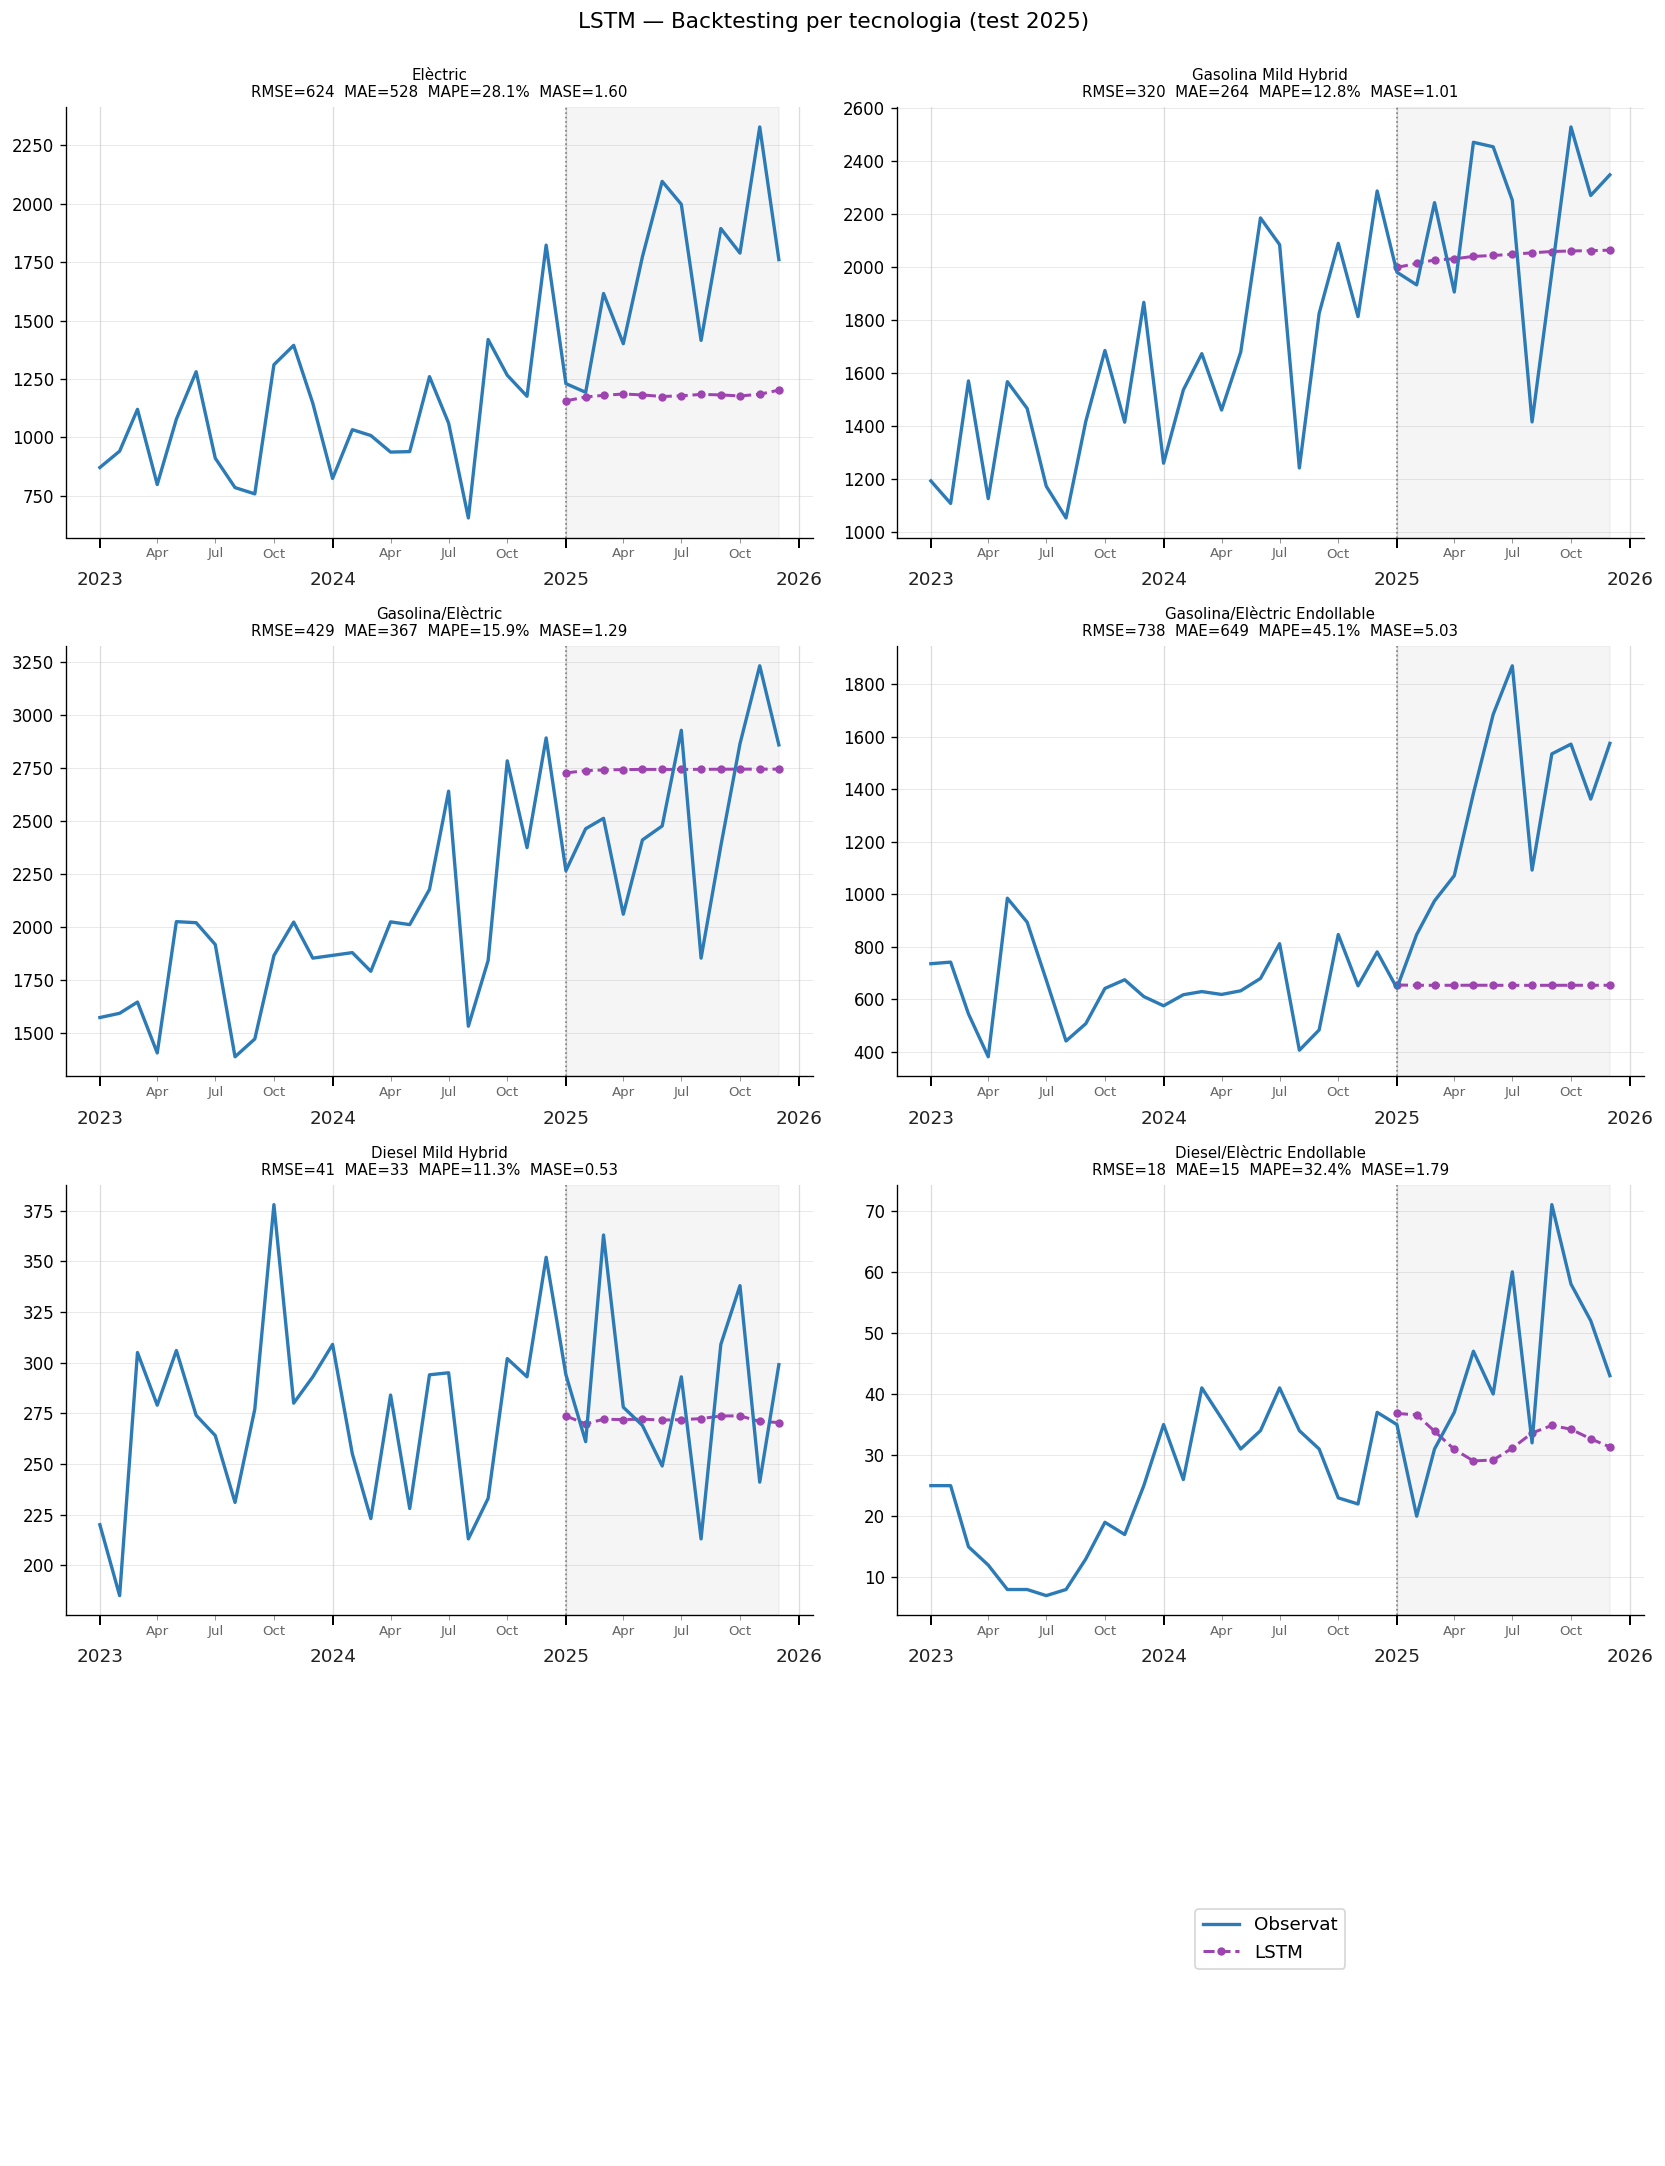

In [6]:
from plotting import plot_backtest_per_tech

SUB_TECHS = [t for t in TECNOLOGIES if t != 'Total']
plot_backtest_per_tech(
    pivot_train, pivot_test, df_forecasts, df_metrics,
    tecnologies=SUB_TECHS, model_name='LSTM',
    save_path=FIGURES_DIR / 'fig_lstm_backtest_per_tech.png',
    color_pred='#9e44b0',
)
plt.show()

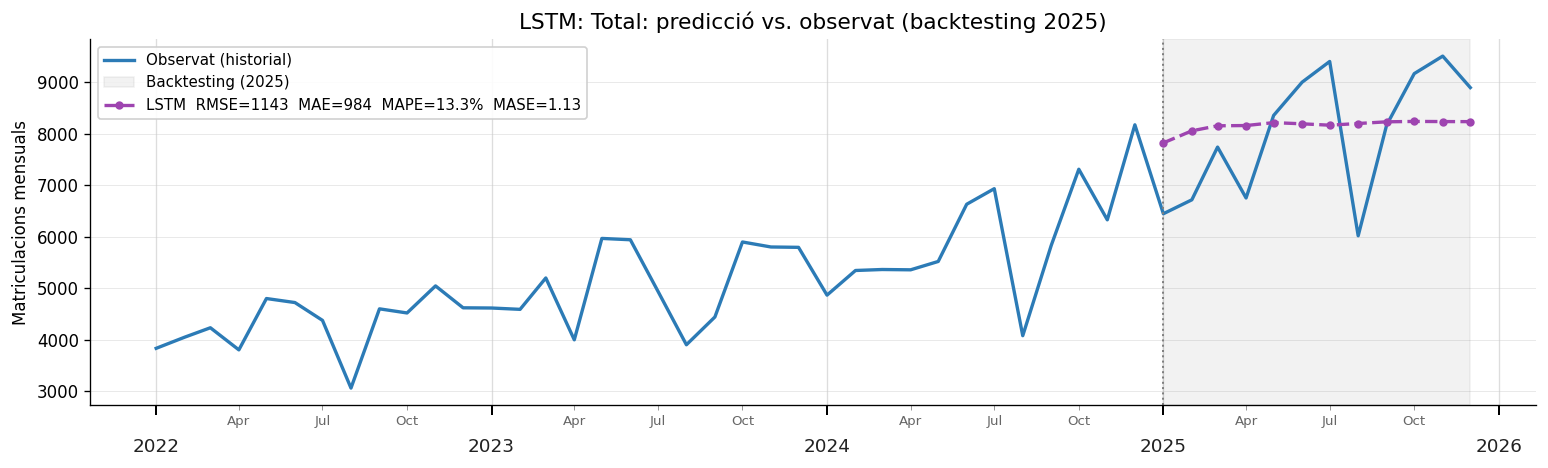

In [7]:
tech = 'Total'
sub  = df_forecasts[df_forecasts['Tecnologia'] == tech].sort_values('date')

fig, ax = plt.subplots(figsize=(13, 4))

y_train_plot   = pivot_train[tech].iloc[-36:]
y_test_plot    = pivot_test[tech]
observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
ax.plot(observed_dates, observed_vals, color='#2c7bb6', lw=2, label='Observat (historial)')

ax.axvspan(pivot_test.index[0], pivot_test.index[-1], alpha=0.10, color='gray', label='Backtesting (2025)')
ax.axvline(pivot_test.index[0], color='gray', ls=':', lw=1.2)

m_total = df_metrics[df_metrics['Tecnologia'] == tech].iloc[0]
label = (f'LSTM  RMSE={m_total["RMSE"]:.0f}  MAE={m_total["MAE"]:.0f}  '
         f'MAPE={m_total["MAPE"]:.1f}%  MASE={m_total["MASE"]:.2f}')
ax.plot(pd.to_datetime(sub['date']), sub['predicted'],
        color='#9e44b0', lw=2, ls='--', marker='o', ms=4, label=label)

ax.set_title(f'LSTM: {tech}: predicció vs. observat (backtesting 2025)', fontsize=13)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=9, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_14_lstm_total.png', bbox_inches='tight')
plt.show()

## 5. Walk-forward validation (rolling-origin)

13 origins per sèrie (`initial=60`, `step=3`, `horizon=12`). A cada fold es reentrenen 300 èpoques sobre la finestra expandida. **Cost aproximat: ~60s per fold × 13 folds × 7 tecnologies ≈ 90 minuts**. Es desa el CSV de resultats per evitar recomputar.

In [8]:
from evaluation import walk_forward_cv_full

pivot_full = pd.concat([pivot_train, pivot_test]).sort_index()

def lstm_fn(train_series):
    arr = train_series.values
    if len(arr) <= WINDOW_SIZE:
        return np.zeros(H)
    torch.manual_seed(RANDOM_SEED)
    model_w, scaler_w = train_lstm(arr)
    return recursive_forecast(model_w, scaler_w, arr, steps=H)

import time
wfv_metric_rows  = []
wfv_forecast_rows = []
print('Walk-forward LSTM (initial=60, step=3, horizon=12)...')
t0 = time.time()
for tech in TECNOLOGIES:
    t_start = time.time()
    series = pivot_full[tech].dropna()
    m_df, f_df = walk_forward_cv_full(series, lstm_fn, initial=60, step=3, horizon=H)
    m_df['Tecnologia'] = tech
    m_df['Model']      = 'LSTM'
    f_df['Tecnologia'] = tech
    f_df['Model']      = 'LSTM'
    wfv_metric_rows.append(m_df)
    wfv_forecast_rows.append(f_df)
    mase_mean = m_df['MASE'].mean() if 'MASE' in m_df.columns else float('nan')
    print(f'  {tech:35s}: {len(m_df)} folds, MASE_mean={mase_mean:.2f}, {time.time()-t_start:.0f}s')
print(f'Total: {(time.time()-t0)/60:.1f} min')

df_wfv_metrics   = pd.concat(wfv_metric_rows, ignore_index=True)
df_wfv_forecasts = pd.concat(wfv_forecast_rows, ignore_index=True)

wfv_agg = (df_wfv_metrics.dropna(subset=['MASE'])
           .groupby('Tecnologia')[['RMSE', 'MAE', 'MAPE', 'MASE']]
           .mean().round(2).reset_index())
print('\nMitjana WFV per tecnologia:')
display(wfv_agg.set_index('Tecnologia'))

Walk-forward LSTM (initial=60, step=3, horizon=12)...


  Elèctric                           : 13 folds, MASE_mean=0.78, 77s


  Gasolina Mild Hybrid               : 13 folds, MASE_mean=1.09, 74s


  Gasolina/Elèctric                  : 13 folds, MASE_mean=1.42, 73s


  Gasolina/Elèctric Endollable       : 13 folds, MASE_mean=1.70, 73s


  Diesel Mild Hybrid                 : 13 folds, MASE_mean=0.65, 69s


  Diesel/Elèctric Endollable         : 13 folds, MASE_mean=1.57, 63s


  Total                              : 13 folds, MASE_mean=1.10, 71s
Total: 8.3 min

Mitjana WFV per tecnologia:


,RMSE,MAE,MAPE,MASE
Tecnologia,,,,
Diesel Mild Hybrid,51.78,42.24,16.43,0.65
Diesel/Elèctric Endollable,12.85,10.93,55.35,1.57
Elèctric,337.14,277.93,23.64,0.78
Gasolina Mild Hybrid,319.49,262.99,15.98,1.09
Gasolina/Elèctric,431.47,361.65,18.86,1.42
Gasolina/Elèctric Endollable,259.72,210.26,25.14,1.70
Total,1121.51,935.89,15.92,1.10


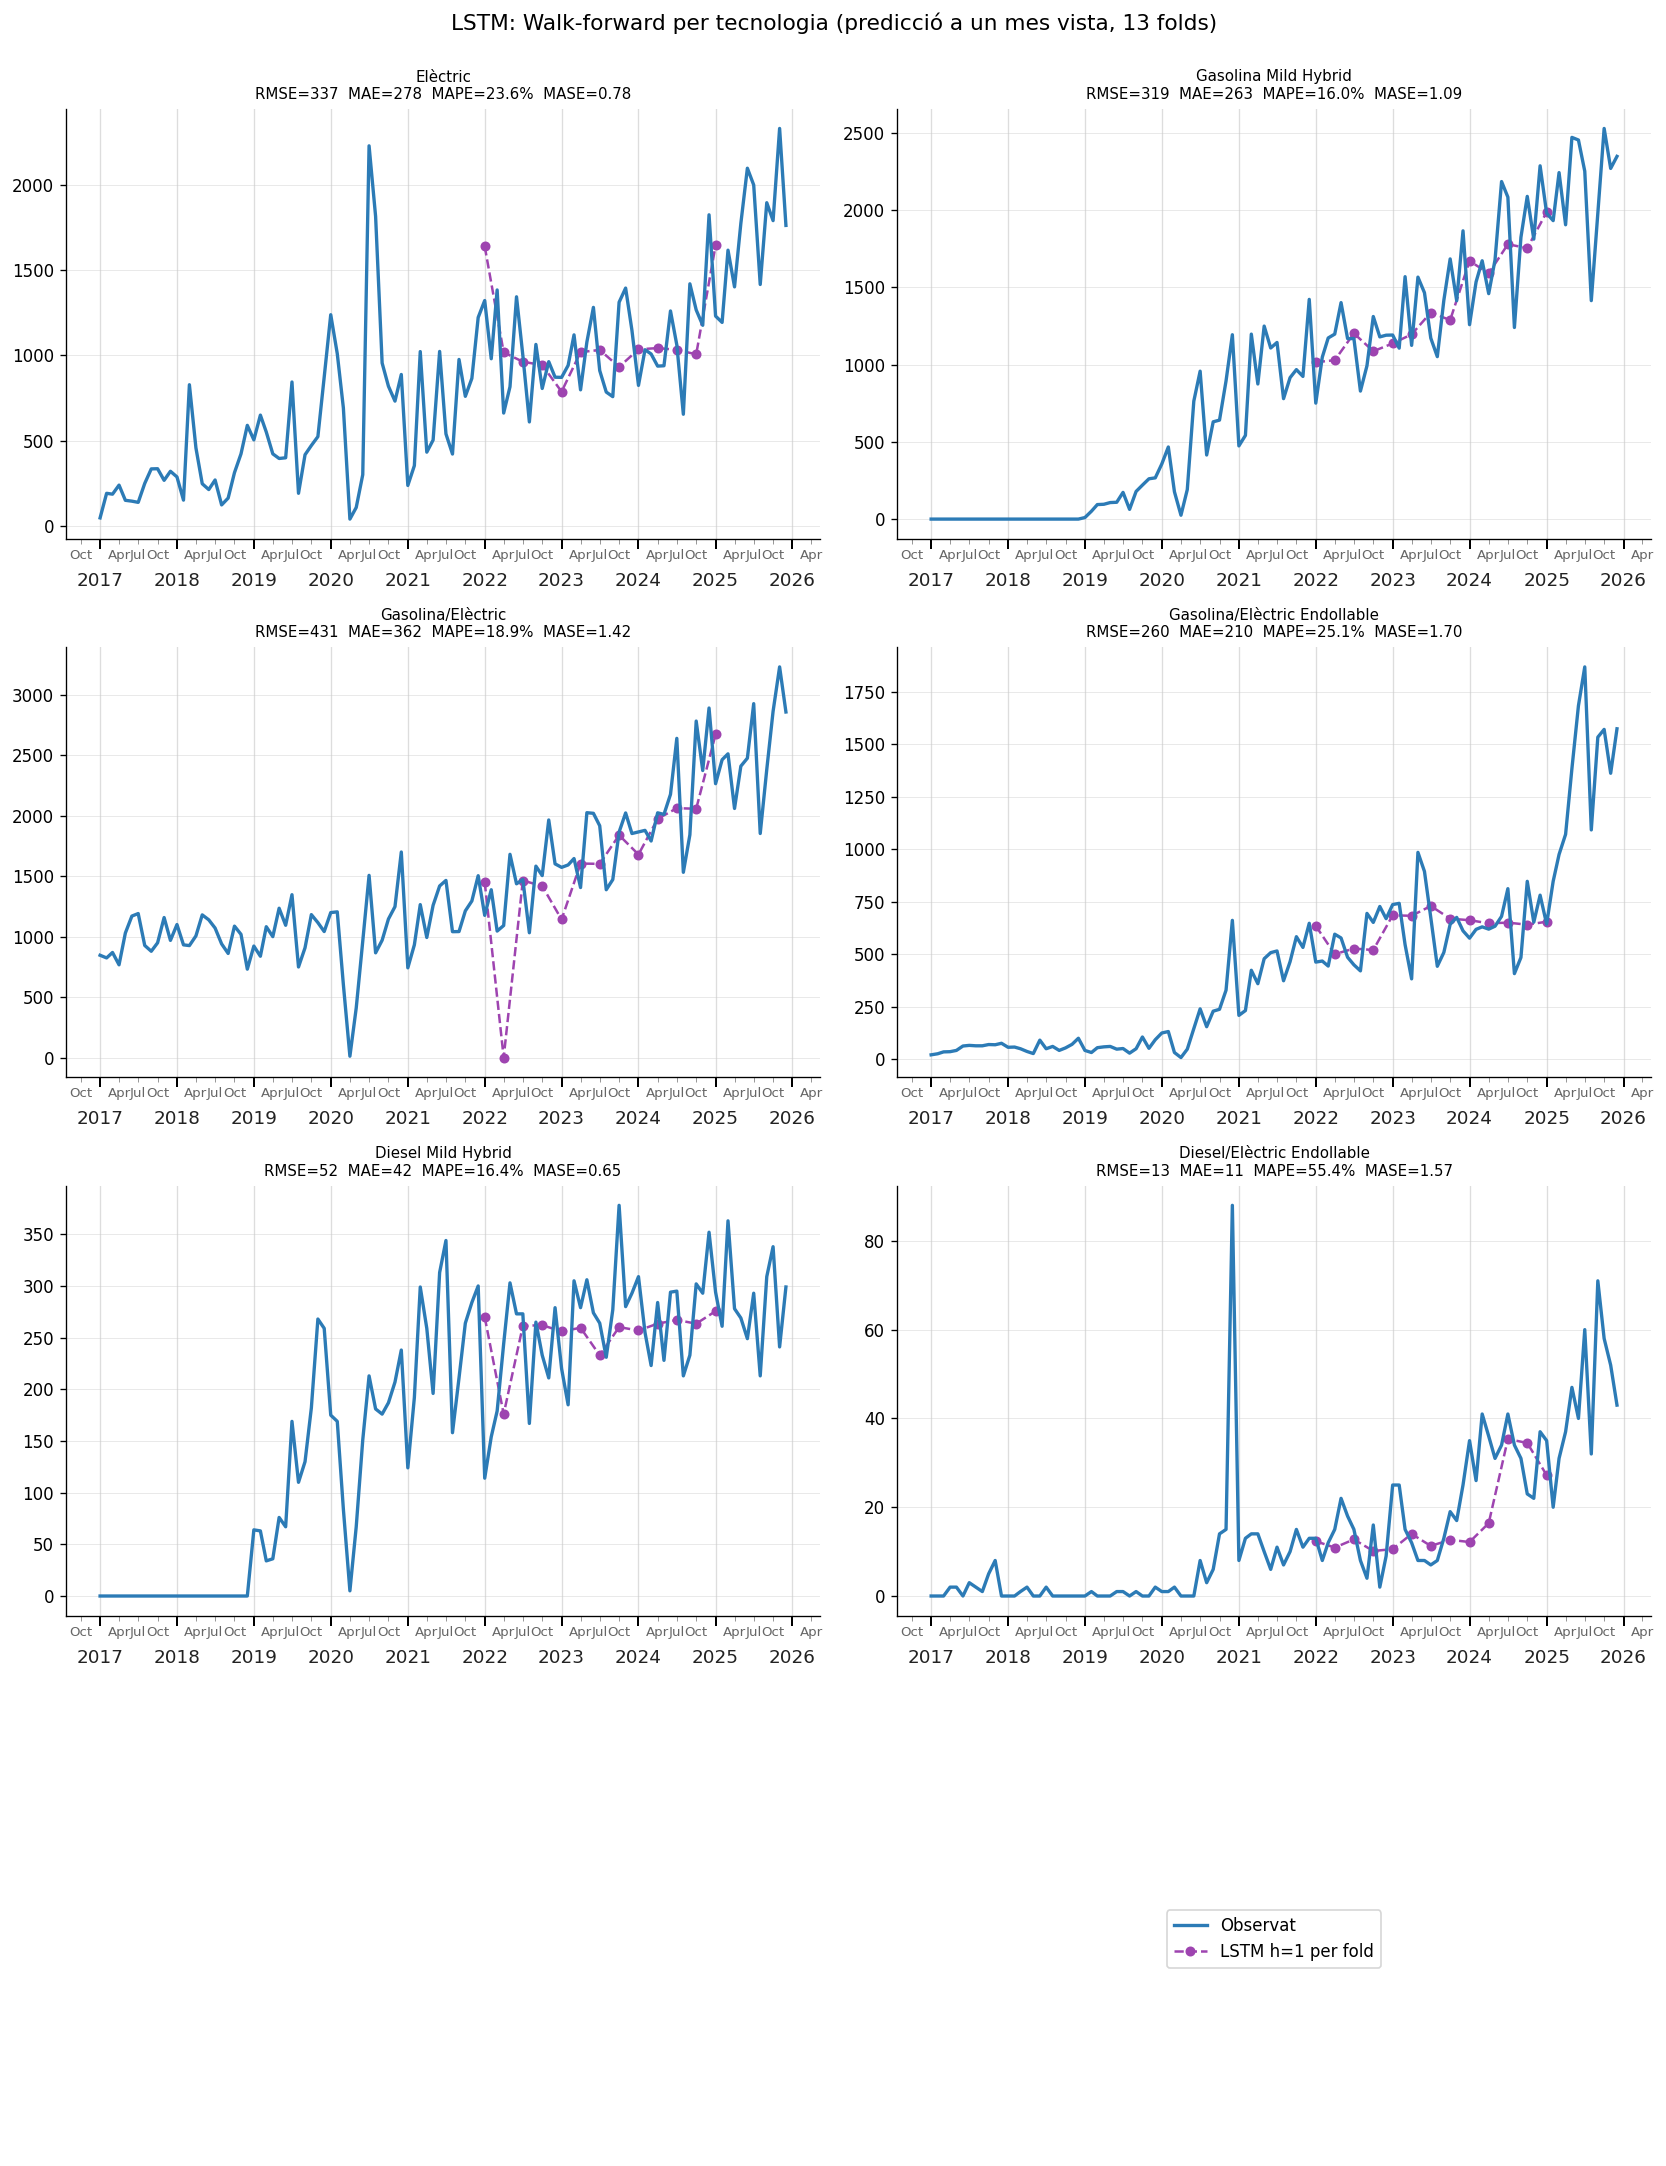

In [9]:
from plotting import plot_wfv_per_tech

SUB_TECHS = [t for t in TECNOLOGIES if t != 'Total']
plot_wfv_per_tech(
    pivot_full, df_wfv_forecasts, wfv_agg,
    tecnologies=SUB_TECHS, model_name='LSTM',
    save_path=FIGURES_DIR / 'fig_lstm_wfv_per_tech.png',
    color_pred='#9e44b0',
)
plt.show()

## 6. Guardar resultats

In [10]:
df_forecasts.to_csv(RESULTS_DIR / 'lstm_forecasts.csv', index=False)
df_metrics.to_csv(RESULTS_DIR  / 'lstm_metrics.csv',   index=False)
df_wfv_metrics.to_csv(RESULTS_DIR / 'lstm_wfv_metrics.csv', index=False)
df_wfv_forecasts.to_csv(RESULTS_DIR / 'lstm_wfv_forecasts.csv', index=False)
print('Guardats:')
print('  lstm_forecasts.csv, lstm_metrics.csv')
print('  lstm_wfv_metrics.csv, lstm_wfv_forecasts.csv')

Guardats:
  lstm_forecasts.csv, lstm_metrics.csv
  lstm_wfv_metrics.csv, lstm_wfv_forecasts.csv
